# Customer Segmentation Using RFM Analysis and K-Means Clustering

In this project, we segment retail customers based on their purchasing behaviour using the **Online Retail II** dataset (covering transactions between December 2009 and December 2011).

Because the dataset does not have predefined customer labels, this is an **unsupervised learning** problem. We clean the raw transaction records, aggregate them to the customer level using **RFM (Recency, Frequency, Monetary)** metrics across the full historical period, and group customers into distinct segments using **K-Means Clustering**.

## 1. Importing Libraries and Loading the Dataset
We start by importing the required libraries and loading the dataset.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import plotly.express as px

file_path = "online_retail_II.csv"

df_raw = pd.read_csv(file_path)

print(f"Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

Dataset Shape: 1,067,371 rows, 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Initial Data Inspection
Before cleaning the data, let's check the data types, missing value counts, and the date range of the dataset.

In [4]:

print("\nMissing Values per Column:")
print(df_raw.isna().sum())



Missing Values per Column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


## 3. Data Cleaning and Preprocessing

We first recover missing information using existing relationships in the table:

1. We drop the `Country` column completely, since it's useless in the current scope.
2. Since each `StockCode` corresponds to an unique item, we fill missing `Description` values using `StockCode` by forward-fill and backward-fill.
2. All items on the same `Invoice` belong to the same buyer. So we fill missing `Customer ID` values using `Invoice` by forward-fill and backward-fill.
3. Rows that still lack a `Customer ID` or `Description` cannot be linked to an identifiable customer or item, so we drop them.
4. In the raw data, the same `StockCode` sometimes has different descriptions. We map each `StockCode` to its first appearing description to maintain consistency.
5. Because `Customer ID` originally contained `NaN` values, Pandas loaded it as a decimal. We convert it to a string so it acts purely as an identifier.

In [5]:
df_clean = df_raw.copy()

# 1. Recover missing Description values using the same StockCode
df_clean["Description"] = (
    df_clean.groupby("StockCode")["Description"]
    .transform(lambda x: x.ffill().bfill())
)

# 2. Recover missing Customer ID values using the same Invoice
df_clean["Customer ID"] = (
    df_clean.groupby("Invoice")["Customer ID"]
    .transform(lambda x: x.ffill().bfill())
)

# 3. Drop rows where Customer ID or Description is still missing
df_clean = df_clean.dropna(subset=["Customer ID", "Description"]).copy()

# 4. Map each StockCode to its single most common Description

def resolve_tie_chronological(series):
    modes = series.mode()
    if len(modes) == 1:
        return modes.iloc[0]
    for val in series:
        if val in modes.values:
            return val
    return modes.iloc[0]  # Fallback

stock_desc_map = (
    df_clean.groupby("StockCode")["Description"]
    .agg(resolve_tie_chronological)
)
df_clean["Description"] = df_clean["StockCode"].map(stock_desc_map)

# 5. Convert Customer ID from float to str 
df_clean["Customer ID"] = df_clean["Customer ID"].astype(int).astype(str)

#6. Drop the Country columnn
df_clean.drop(columns=["Country"])

print(f"\nRemaining rows and columns: {df_clean.shape}")
df_clean.head()


Remaining rows and columns: (824364, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


## 4. Further Preprocessing

We filter the dataset to retain only valid, positive purchases by removing rows containing invalid invoices and non-positive price/quantity values, since excluding these negative values prevents errors during logarithmic transformation and ensures Euclidean distances in K-Means are not distorted.

We also compute `TotalPrice = Quantity * Price` for each row for our RFM features later.

In [6]:
# Check how many anomalous rows exist before filtering
cancellations_count = df_clean["Invoice"].str.startswith("C", na=False).sum()
neg_qty_count = (df_clean["Quantity"] <= 0).sum()
neg_price_count = (df_clean["Price"] <= 0).sum()

print(f"Cancellation rows ('C' prefix in Invoice col): {cancellations_count:,}")
print(f"Rows with Quantity <= 0:     {neg_qty_count:,}")
print(f"Rows with Price <= 0:        {neg_price_count:,}")

# Keep only valid positive purchases
df_valid = df_clean[
    (~df_clean["Invoice"].str.startswith("C", na=False)) &
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

# Calculate line-item spend
df_valid["TotalPrice"] = df_valid["Quantity"] * df_valid["Price"]

print(f"\nRemaining rows and columns: {df_valid.shape}")
df_valid.head()

Cancellation rows ('C' prefix in Invoice col): 18,744
Rows with Quantity <= 0:     18,744
Rows with Price <= 0:        71

Remaining rows and columns: (805549, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


## 5. Customer-Level RFM Feature Engineering
We group `df_valid` by `Customer ID` to consolidate multiple invoice rows into a single row per unique customer, enabling customer-level segmentation.

We calculate three features for every customer:
* **Recency:** Days since the customer's last purchase.
* **Frequency:** Total number of unique invoices(transactions) for that customer.
* **Monetary:** Total spend across the customer's purchase history.

In [7]:
# Ensure InvoiceDate is datetime
df_valid["InvoiceDate"] = pd.to_datetime(df_valid["InvoiceDate"])

# Define reference date as 1 day after the latest transaction date
latest_date = df_valid["InvoiceDate"].max()
reference_date = pd.to_datetime(latest_date.date()) + pd.Timedelta(days=1)

print(f"Latest Transaction Date: {latest_date}")
print(f"Reference Date Used:     {reference_date}")

# Aggregate to customer level
rfm_df = df_valid.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

print(f"\nTotal Unique Customers: {rfm_df.shape[0]:,}")
display(rfm_df.head())


Latest Transaction Date: 2011-12-09 12:50:00
Reference Date Used:     2011-12-10 00:00:00

Total Unique Customers: 5,878


,Customer ID,Recency,Frequency,Monetary
0,12346,325,12,77556.46
1,12347,2,8,5633.32
2,12348,75,5,2019.40
3,12349,18,4,4428.69
4,12350,310,1,334.40


## 6. Handling Skewness of data and scaling features

### 6.1 Applying Log Transformation
Looking at the summary statistics above, `Frequency` and `Monetary` columns are skewed, since most customers only buy a few times, while a handful of them buy in huge quantities.

Raw Feature Skewness:
Recency       0.89
Frequency    12.64
Monetary     25.31
dtype: float64

Transformed Feature Skewness:
Recency_Log     -0.55
Frequency_Log    1.00
Monetary_Log     0.27
dtype: float64


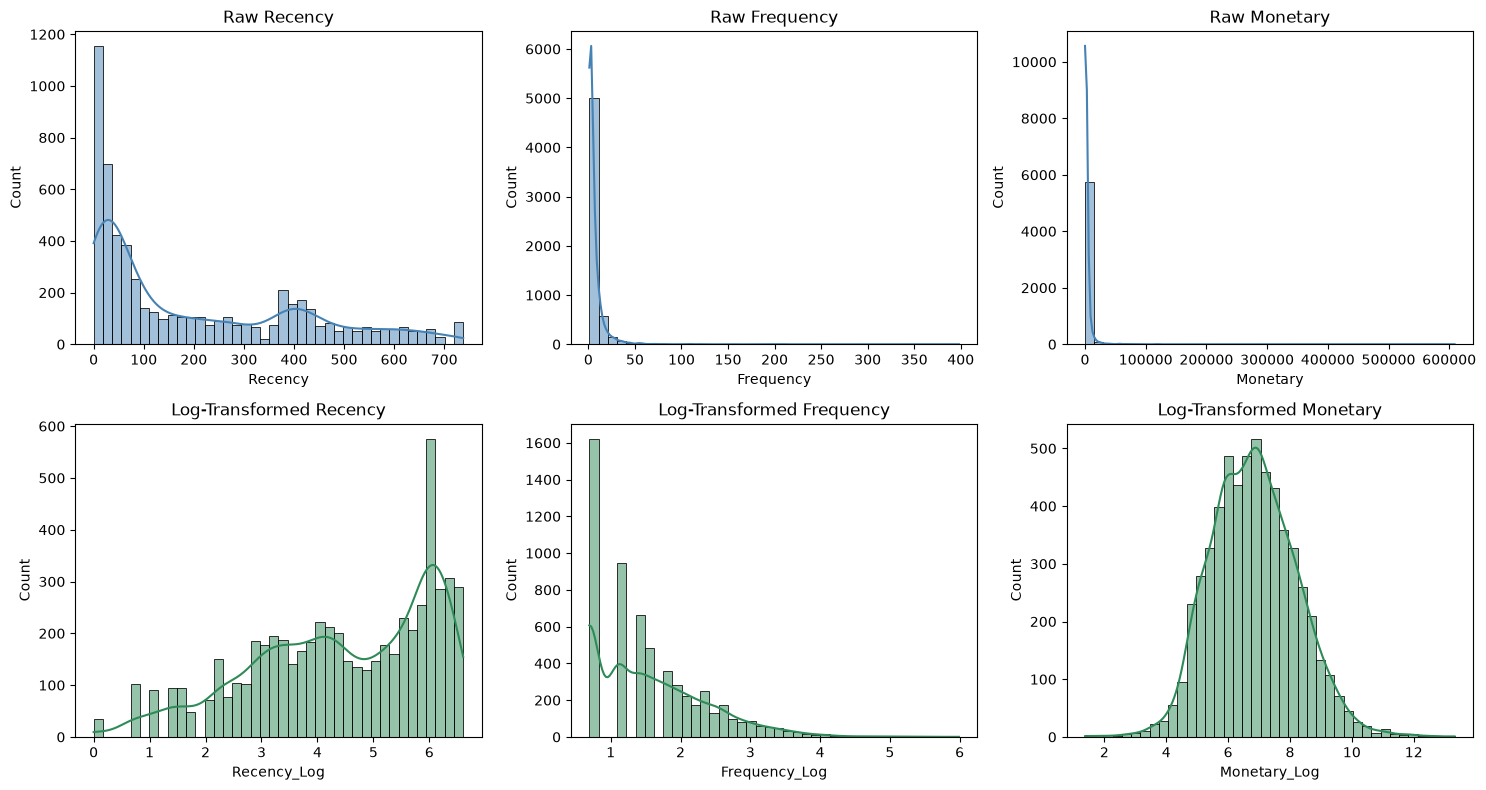

In [8]:
print("Raw Feature Skewness:")
print(rfm_df[["Recency", "Frequency", "Monetary"]].skew().round(2))

# Create a copy for transformed features
rfm_model_df = rfm_df[["Customer ID"]].copy()
rfm_model_df["Recency_Log"] = np.log1p(rfm_df["Recency"])
rfm_model_df["Frequency_Log"] = np.log1p(rfm_df["Frequency"])
rfm_model_df["Monetary_Log"] = np.log1p(rfm_df["Monetary"])

print("\nTransformed Feature Skewness:")
print(rfm_model_df[["Recency_Log", "Frequency_Log", "Monetary_Log"]].skew().round(2))

# Visualise distributions before and after transformation
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
raw_cols = ["Recency", "Frequency", "Monetary"]
log_cols = ["Recency_Log", "Frequency_Log", "Monetary_Log"]

for i in range(3):
    sns.histplot(rfm_df[raw_cols[i]], bins=40, kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Raw {raw_cols[i]}")
    
    sns.histplot(rfm_model_df[log_cols[i]], bins=40, kde=True, ax=axes[1, i], color="seagreen")
    axes[1, i].set_title(f"Log-Transformed {raw_cols[i]}")

plt.tight_layout()
plt.show()

### 6.2 Feature Scaling
Even after log transformation, the numeric ranges of Recency, Frequency, and Monetary are different. So we standardise them using `StandardScaler`.

In [9]:
feature_cols = ["Recency_Log", "Frequency_Log", "Monetary_Log"]
X_raw = rfm_model_df[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=["Recency_Scaled", "Frequency_Scaled", "Monetary_Scaled"]
)

print("Scaled Features Preview:")
display(X_scaled_df.head())

Scaled Features Preview:


,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
0,0.849280,1.254496,3.186625
1,-2.089437,0.800166,1.297127
2,-0.063475,0.299207,0.558100
3,-0.932434,0.073946,1.123790
4,0.819754,-1.058146,-0.735888


## 7. Choosing the Number of Clusters (K)
Because K-Means requires us to specify the number of clusters $K$ beforehand, we evaluate different values of $K$ using two metrics:
1. **Elbow Method (Inertia):** Measures the within-cluster sum of squared distances. Lower inertia means more compact clusters. Since inertia always decreases as $K$ grows, we look for the "elbow" where the drop slows down.
2. **Silhouette Score:** Measures how similar a customer is to their own cluster compared to other clusters. Higher values mean cleaner separation between groups.

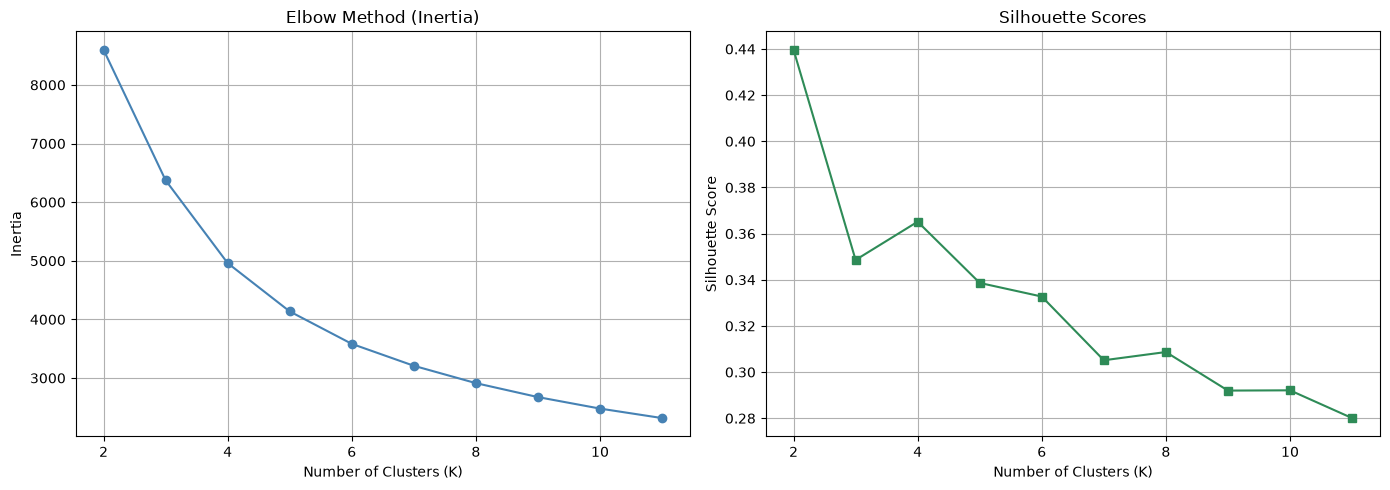

In [10]:
inertia = []
silhouette_scores = []
K_range = range(2, 12)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42,n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, cluster_labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Elbow Method
ax1.plot(K_range, inertia, marker="o", linestyle="-", color="steelblue")
ax1.set_title("Elbow Method (Inertia)")
ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("Inertia")
ax1.grid(True)

# Plot 2: Silhouette Scores
ax2.plot(K_range, silhouette_scores, marker="s", linestyle="-", color="seagreen")
ax2.set_title("Silhouette Scores")
ax2.set_xlabel("Number of Clusters (K)")
ax2.set_ylabel("Silhouette Score")
ax2.grid(True)

plt.tight_layout()
plt.show()

## 8. Training the Model
We now train the final K-Means model with `n_clusters=4` and return the assigned cluster labels (`0`, `1`, `2`, `3`) for all 5,878 customers in one step.

In [11]:
optimal_k = 4
model = KMeans(n_clusters=optimal_k, random_state=42,n_init=10)

# Fit model and assign cluster labels back to our customer dataframe
cluster_labels = model.fit_predict(X_scaled)
rfm_df["Cluster"] = cluster_labels

print("Customer Count per Cluster:")
print(rfm_df["Cluster"].value_counts().sort_index())

Customer Count per Cluster:
Cluster
0    2055
1    1478
2    1228
3    1117
Name: count, dtype: int64


## 9. Interactive 3D Cluster Plot
Since we have exactly three features in our dataset, we build an interactive 3D scatter plot using Plotly so we can visualise the clusters.

In [16]:
import plotly.graph_objects as go
import plotly.express as px

# Prepare the plotting dataframe (sorted by Cluster so the legend is ordered 0, 1, 2, 3)
plotly_df = X_scaled_df.copy()
plotly_df["Cluster"] = rfm_df["Cluster"].astype(str)
plotly_df["Customer ID"] = rfm_df["Customer ID"].values
plotly_df["Recency"] = rfm_df["Recency"].values
plotly_df["Frequency"] = rfm_df["Frequency"].values
plotly_df["Monetary"] = rfm_df["Monetary"].round(2).values
plotly_df = plotly_df.sort_values("Cluster")

# High-contrast color palette
palette = ["#00CC96", "#EF553B", "#636EFA", "#AB63FA"]

# 1. Main 3D customer scatter plot
fig = px.scatter_3d(
    plotly_df,
    x="Recency_Scaled",
    y="Frequency_Scaled",
    z="Monetary_Scaled",
    color="Cluster",
    color_discrete_sequence=palette,
    custom_data=["Customer ID", "Recency", "Frequency", "Monetary", "Cluster"],
    title="<b>3D Customer Segmentation Space (K = 4)</b>",
    template="plotly_dark",
    opacity=0.75
)

# Refine customer markers and format a clean hover card
fig.update_traces(
    marker=dict(
        size=3.5,
        line=dict(width=0.4, color="#111111")
    ),
    hovertemplate=(
        "<b>Customer ID:</b> %{customdata[0]}<br>"
        "<b>Cluster:</b> %{customdata[4]}<br>"
        "<b>Recency:</b> %{customdata[1]} days<br>"
        "<b>Frequency:</b> %{customdata[2]} orders<br>"
        "<b>Monetary:</b> £%{customdata[3]:,.2f}"
        "<extra></extra>"
    )
)

# 2. Add Cluster Centroids as large white-bordered diamonds
centroids = model.cluster_centers_
fig.add_trace(
    go.Scatter3d(
        x=centroids[:, 0],
        y=centroids[:, 1],
        z=centroids[:, 2],
        mode="markers",
        marker=dict(
            size=9,
            color="white",
            symbol="diamond",
            line=dict(width=2, color="black")
        ),
        name="Centroids",
        hovertemplate=(
            "<b>Cluster Centroid</b><br>"
            "Recency (Scaled): %{x:.2f}<br>"
            "Frequency (Scaled): %{y:.2f}<br>"
            "Monetary (Scaled): %{z:.2f}"
            "<extra></extra>"
        )
    )
)

# 3. Adjust 3D box aspect ratio, camera distance, and layout
fig.update_layout(
    height=750,
    title=dict(x=0.5, font=dict(size=18)),
    scene=dict(
        xaxis=dict(title="Recency (Scaled)", backgroundcolor="rgb(20, 24, 35)", gridcolor="rgb(60, 65, 80)"),
        yaxis=dict(title="Frequency (Scaled)", backgroundcolor="rgb(20, 24, 35)", gridcolor="rgb(60, 65, 80)"),
        zaxis=dict(title="Monetary (Scaled)", backgroundcolor="rgb(20, 24, 35)", gridcolor="rgb(60, 65, 80)"),
        aspectmode="cube",
        camera=dict(
            eye=dict(x=1.6, y=1.6, z=1.2)  # Pulls camera back so nothing is cut off
        )
    ),
    legend=dict(
        title="<b>Segment</b>",
        yanchor="top", y=0.9,
        xanchor="left", x=0.02,
        bgcolor="rgba(0,0,0,0.5)",
        itemsizing="constant"
    ),
    margin=dict(l=10, r=10, b=10, t=50)
)

fig